# Bar Inventory Demand Forecast and Par-Level Planner

This notebook turns the supplied movement history into a first-pass forecast, a par-level target for each bar and brand, and a manager's replenishment watchlist. The code favors clear assumptions that can be changed by the hotel team.

The source is a set of dated records, not a complete daily sales ledger. A date without a row may mean no activity or an unrecorded movement. The first pass treats it as zero recorded consumption and displays record coverage beside each recommendation.


## 1. Setup

The path below checks the original download folder first, then looks beside the notebook. The lead time, review cycle, service level, balance tolerance, and planning increment are adjustable assumptions.

In [1]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 30)
possible_paths = [
    Path(r"C:\Users\Anindya Pan\Downloads\Consumption Dataset - Dataset.csv"),
    Path("Consumption Dataset - Dataset.csv"),
    Path("data/Consumption Dataset - Dataset.csv"),
]
DATA_PATH = next((p for p in possible_paths if p.exists()), possible_paths[0])

LEAD_TIME_DAYS = 3
REVIEW_PERIOD_DAYS = 7
SERVICE_LEVEL = 0.95
FORECAST_WINDOW_WEEKS = 8
VALIDATION_WEEKS = 8
BALANCE_TOLERANCE_ML = 1.0
PAR_ROUNDING_ML = 50

GROUP_COLS = ["Bar Name", "Alcohol Type", "Brand Name"]
TIME_COL = "Date Time Served"
DEMAND_COL = "Consumed (ml)"
MOVEMENT_COLS = [
    "Opening Balance (ml)", "Purchase (ml)",
    DEMAND_COL, "Closing Balance (ml)"
]

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"CSV not found: {DATA_PATH}. Update DATA_PATH or place the file beside this notebook."
    )

# Keep the loaded table intact; all checks below add flags rather than fixing source values.
source_data = pd.read_csv(DATA_PATH)
raw = source_data.copy()

required = {TIME_COL, *GROUP_COLS, *MOVEMENT_COLS}
missing_columns = required.difference(raw.columns)
if missing_columns:
    raise ValueError(f"Missing expected columns: {sorted(missing_columns)}")

raw["source_row_number"] = np.arange(2, len(raw) + 2)
raw["is_exact_duplicate"] = source_data.duplicated(keep=False)

raw[TIME_COL] = pd.to_datetime(raw[TIME_COL], errors="coerce")
for column in MOVEMENT_COLS:
    raw[column] = pd.to_numeric(raw[column], errors="coerce")

raw["Date"] = raw[TIME_COL].dt.normalize()
raw["has_negative_quantity"] = raw[MOVEMENT_COLS].lt(0).any(axis=1)

raw["expected_closing_ml"] = (
    raw["Opening Balance (ml)"] + raw["Purchase (ml)"] - raw[DEMAND_COL]
)
raw["balance_discrepancy_ml"] = (
    raw["Closing Balance (ml)"] - raw["expected_closing_ml"]
)
raw["has_balance_discrepancy"] = (
    raw["balance_discrepancy_ml"].abs() > BALANCE_TOLERANCE_ML
)

required_for_demand = [TIME_COL, *GROUP_COLS, DEMAND_COL]
raw["has_missing_required_field"] = raw[required_for_demand].isna().any(axis=1)

quality_summary = pd.Series({
    "Rows in source file": len(raw),
    "Rows with missing values (any column)": int(raw.isna().any(axis=1).sum()),
    "Rows with invalid timestamps": int(raw[TIME_COL].isna().sum()),
    "Exact duplicate rows": int(raw["is_exact_duplicate"].sum()),
    "Rows with a negative movement or balance": int(raw["has_negative_quantity"].sum()),
    "Rows with missing demand-analysis fields": int(raw["has_missing_required_field"].sum()),
    f"Balance discrepancies over {BALANCE_TOLERANCE_ML:g} ml": int(raw["has_balance_discrepancy"].sum()),
    "Maximum absolute balance discrepancy (ml)": raw["balance_discrepancy_ml"].abs().max(),
}, name="row_count")
display(quality_summary.to_frame())

# Show suspicious rows for review; do not overwrite or silently repair them.
suspicious_mask = (
    raw["is_exact_duplicate"] | raw["has_negative_quantity"]
    | raw["has_balance_discrepancy"] | raw["has_missing_required_field"]
    | raw[TIME_COL].isna()
)
suspicious_columns = [
    "source_row_number", TIME_COL, *GROUP_COLS, *MOVEMENT_COLS,
    "expected_closing_ml", "balance_discrepancy_ml",
    "is_exact_duplicate", "has_negative_quantity", "has_balance_discrepancy",
    "has_missing_required_field",
]
suspicious_records = raw.loc[suspicious_mask, suspicious_columns]
print(f"Flagged records for review: {len(suspicious_records):,}")
display(suspicious_records)

# Demand analysis requires a usable date, item identity, and nonnegative consumption.
analysis_data = raw.dropna(subset=required_for_demand).copy()
negative_demand_mask = analysis_data[DEMAND_COL] < 0
print(f"Negative-consumption rows excluded from demand analysis: {int(negative_demand_mask.sum()):,}")
analysis_data = analysis_data.loc[~negative_demand_mask].copy()
analysis_data["Date"] = analysis_data[TIME_COL].dt.normalize()

print(f"Rows retained for demand analysis: {len(analysis_data):,}")
print(f"Date range: {analysis_data[TIME_COL].min():%Y-%m-%d} to {analysis_data[TIME_COL].max():%Y-%m-%d}")
print(f"Bars: {analysis_data['Bar Name'].nunique()} | Brands: {analysis_data['Brand Name'].nunique()} | "
      f"Bar-brand combinations: {analysis_data[GROUP_COLS].drop_duplicates().shape[0]}")

,row_count
Rows in source file,6575.00
Rows with missing values (any column),0.00
Rows with invalid timestamps,0.00
Exact duplicate rows,0.00
Rows with a negative movement or balance,0.00
Rows with missing demand-analysis fields,0.00
Balance discrepancies over 1 ml,86.00
Maximum absolute balance discrepancy (ml),9.25


Flagged records for review: 86


,source_row_number,Date Time Served,Bar Name,Alcohol Type,Brand Name,Opening Balance (ml),Purchase (ml),Consumed (ml),Closing Balance (ml),expected_closing_ml,balance_discrepancy_ml,is_exact_duplicate,has_negative_quantity,has_balance_discrepancy,has_missing_required_field
99,101,2023-01-06 13:10:00,Johnson's Bar,Wine,Barefoot,1427.79,0.00,248.86,1180.0,1178.93,1.07,False,False,True,False
125,127,2023-01-07 14:01:00,Taylor's Bar,Whiskey,Jim Beam,2510.00,0.00,494.68,2010.0,2015.32,-5.32,False,False,True,False
143,145,2023-01-08 14:46:00,Taylor's Bar,Rum,Captain Morgan,126.78,1736.61,569.99,1290.0,1293.40,-3.40,False,False,True,False
162,164,2023-01-09 13:49:00,Brown's Bar,Beer,Coors,1860.00,0.00,444.47,1420.0,1415.53,4.47,False,False,True,False
179,181,2023-01-10 20:13:00,Smith's Bar,Beer,Coors,2790.00,1416.82,583.52,3620.0,3623.30,-3.30,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1539,1541,2023-03-25 20:29:00,Smith's Bar,Whiskey,Jim Beam,4480.00,0.00,303.12,4180.0,4176.88,3.12,False,False,True,False
1559,1561,2023-03-26 18:54:00,Smith's Bar,Whiskey,Jim Beam,4180.00,831.13,338.33,4670.0,4672.80,-2.80,False,False,True,False
1567,1569,2023-03-26 11:47:00,Taylor's Bar,Wine,Barefoot,4568.60,0.00,565.34,4000.0,4003.26,-3.26,False,False,True,False
1583,1585,2023-03-27 15:36:00,Brown's Bar,Whiskey,Jim Beam,2120.00,1653.21,265.90,3510.0,3507.31,2.69,False,False,True,False


Negative-consumption rows excluded from demand analysis: 0
Rows retained for demand analysis: 6,575
Date range: 2023-01-01 to 2024-01-01
Bars: 6 | Brands: 16 | Bar-brand combinations: 96


## 2. Understand the recorded movement

The charts summarize recorded consumption; they are not adjusted for different logging frequencies.

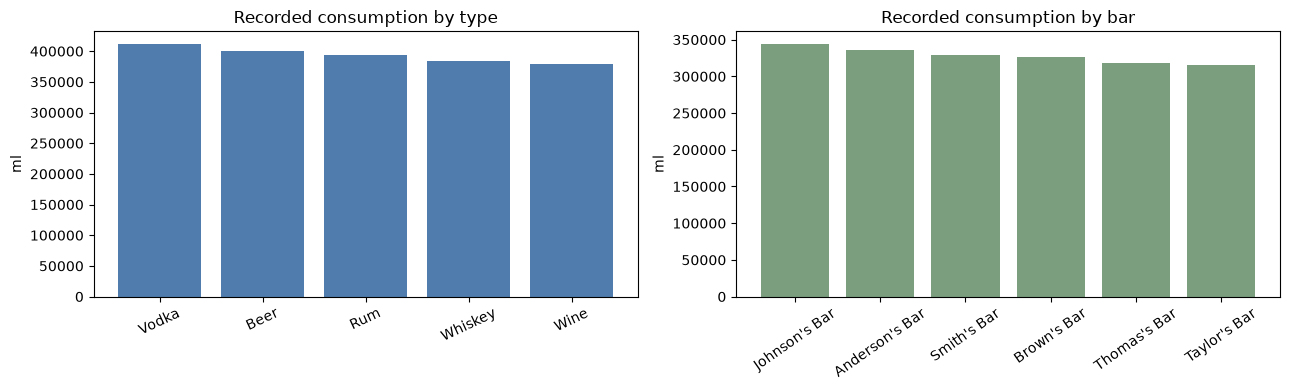

Average rows per bar-brand combination: 68.5


,Alcohol Type,Consumed (ml)
2,Vodka,411759.71
0,Beer,399498.39
1,Rum,393266.84
3,Whiskey,384754.46
4,Wine,379402.26


In [3]:
by_type = (analysis_data.groupby("Alcohol Type", as_index=False)[DEMAND_COL]
           .sum().sort_values(DEMAND_COL, ascending=False))
by_bar = (analysis_data.groupby("Bar Name", as_index=False)[DEMAND_COL]
          .sum().sort_values(DEMAND_COL, ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(by_type["Alcohol Type"], by_type[DEMAND_COL], color="#4f7cac")
axes[0].set(title="Recorded consumption by type", ylabel="ml")
axes[0].tick_params(axis="x", rotation=25)
axes[1].bar(by_bar["Bar Name"], by_bar[DEMAND_COL], color="#7a9e7e")
axes[1].set(title="Recorded consumption by bar", ylabel="ml")
axes[1].tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

combination_count = analysis_data[GROUP_COLS].drop_duplicates().shape[0]
print("Average rows per bar-brand combination:",
      round(len(analysis_data) / combination_count, 1))
display(by_type)

## 3. Make daily series and check logging coverage

Rows for the same bar, brand, and calendar date are summed. Missing dates are filled with zero recorded demand only as a working assumption: a missing row may mean zero activity or incomplete logging. Coverage remains visible beside each item. Negative consumption is reported above and excluded from demand analysis rather than silently changed to zero.

In [4]:
observed = (analysis_data.groupby([*GROUP_COLS, "Date"], as_index=False)[DEMAND_COL]
            .sum().rename(columns={DEMAND_COL: "demand_ml"}))
dates = pd.date_range(analysis_data["Date"].min(), analysis_data["Date"].max(), freq="D")
items = analysis_data[GROUP_COLS].drop_duplicates()
grid = items.merge(pd.DataFrame({"Date": dates}), how="cross")
daily = grid.merge(observed, on=[*GROUP_COLS, "Date"], how="left")
daily["observed_record"] = daily["demand_ml"].notna()
daily["demand_ml"] = daily["demand_ml"].fillna(0)

coverage = (daily.groupby(GROUP_COLS, as_index=False)
            .agg(recorded_days=("observed_record", "sum"),
                 calendar_days=("Date", "count")))
coverage["coverage_pct"] = 100 * coverage["recorded_days"] / coverage["calendar_days"]
display(coverage.sort_values("coverage_pct").head(10))

,Bar Name,Alcohol Type,Brand Name,recorded_days,calendar_days,coverage_pct
66,Taylor's Bar,Beer,Heineken,40,366,10.928962
17,Brown's Bar,Beer,Coors,46,366,12.568306
48,Smith's Bar,Beer,Budweiser,46,366,12.568306
49,Smith's Bar,Beer,Coors,47,366,12.841530
82,Thomas's Bar,Beer,Heineken,47,366,12.841530
80,Thomas's Bar,Beer,Budweiser,48,366,13.114754
0,Anderson's Bar,Beer,Budweiser,48,366,13.114754
16,Brown's Bar,Beer,Budweiser,49,366,13.387978
50,Smith's Bar,Beer,Heineken,50,366,13.661202
32,Johnson's Bar,Beer,Budweiser,52,366,14.207650


## 4. Compare a simple forecast with a baseline

The candidate forecast is the mean of the previous eight complete weeks; the baseline is the previous week's demand. I use the first eight weeks after the eight-week warm-up for chronological rolling validation. That makes the selected method available before the simulation starts. WAPE is weighted absolute percentage error; lower is better. If total actual demand is zero, the percentage metrics are reported as unavailable and MAE is used as the selection fallback.

In [5]:
first_date = daily["Date"].min()
end_date = daily["Date"].max()
first_week_end = first_date + pd.Timedelta(days=(6 - first_date.weekday()) % 7)
last_complete_week_end = end_date - pd.Timedelta(days=(end_date.weekday() + 1) % 7)

checks = []
for key, item_days in daily.groupby(GROUP_COLS, sort=False):
    weekly = (item_days.set_index("Date")["demand_ml"]
              .resample("W-SUN").sum().sort_index())
    weekly = weekly.loc[
        (weekly.index > first_week_end) & (weekly.index <= last_complete_week_end)
    ]
    validation_weeks = weekly.index[
        FORECAST_WINDOW_WEEKS:FORECAST_WINDOW_WEEKS + VALIDATION_WEEKS
    ]

    for week_end in validation_weeks:
        history = weekly.loc[weekly.index < week_end]
        if len(history) < FORECAST_WINDOW_WEEKS:
            continue
        checks.append({
            **dict(zip(GROUP_COLS, key)),
            "week_ending": week_end,
            "actual": float(weekly.loc[week_end]),
            "moving_average": float(history.tail(FORECAST_WINDOW_WEEKS).mean()),
            "last_week": float(history.iloc[-1]),
        })

validation = pd.DataFrame(checks)
if validation.empty:
    raise ValueError("Not enough weekly history to validate the forecasts.")

def metrics(actual, predicted):
    errors = np.abs(actual - predicted)
    total_actual = np.abs(actual).sum()
    return {
        "MAE (ml/item-week)": errors.mean(),
        "WAPE (%)": 100 * errors.sum() / total_actual if total_actual else np.nan,
        "Bias (%)": (
            100 * (predicted - actual).sum() / total_actual
            if total_actual else np.nan
        ),
    }

actual = validation["actual"].to_numpy()
scorecard = pd.DataFrame([
    {"Forecast": "Eight-week average",
     **metrics(actual, validation["moving_average"].to_numpy())},
    {"Forecast": "Previous week",
     **metrics(actual, validation["last_week"].to_numpy())},
])

# Choose the lowest WAPE; break ties with MAE. If WAPE is undefined, use MAE.
if scorecard["WAPE (%)"].notna().any():
    eligible_scores = scorecard.dropna(subset=["WAPE (%)"])
    winner = eligible_scores.sort_values(
        ["WAPE (%)", "MAE (ml/item-week)"]
    ).iloc[0]
    SELECTION_CRITERION = "Lowest WAPE; ties broken by MAE"
else:
    winner = scorecard.sort_values("MAE (ml/item-week)").iloc[0]
    SELECTION_CRITERION = "Lowest MAE because total validation demand is zero"

SELECTED_FORECAST_METHOD = winner["Forecast"]
SIMULATION_START = validation["week_ending"].max() + pd.Timedelta(days=1)
SIMULATION_END = daily["Date"].max()

print(f"Rolling validation sample: {len(validation):,} item-weeks")
print(scorecard.round(1).to_string(index=False))
print(f"Selection criterion: {SELECTION_CRITERION}")
print(f"Selected forecast: {SELECTED_FORECAST_METHOD}")
print(f"Simulation period: {SIMULATION_START:%Y-%m-%d} to {SIMULATION_END:%Y-%m-%d}")

Rolling validation sample: 768 item-weeks
          Forecast  MAE (ml/item-week)  WAPE (%)  Bias (%)
Eight-week average               325.1      85.4       4.8
     Previous week               389.5     102.3       0.1
Selection criterion: Lowest WAPE; ties broken by MAE
Selected forecast: Eight-week average
Simulation period: 2023-04-24 to 2024-01-01


## 5. Forecast demand and set a par target

The selected method is used consistently for the final forecast. Protection Period = Lead Time + Review Interval. Par Level = Expected Demand During Protection Period + Safety Stock. Safety stock uses the recent 56 calendar days' variability and the selected service-level z-score. Par and reorder-point quantities are rounded up to 50 ml for planning; confirm actual purchase pack sizes before ordering.

In [6]:
z_by_service = {0.90: 1.282, 0.95: 1.645, 0.97: 1.881, 0.99: 2.326}
if SERVICE_LEVEL not in z_by_service:
    raise ValueError(f"Choose a service level from {list(z_by_service)}.")
z_score = z_by_service[SERVICE_LEVEL]

def round_up_to_step(quantity_ml):
    return float(max(0, math.ceil(quantity_ml / PAR_ROUNDING_ML) * PAR_ROUNDING_ML))

as_of = analysis_data[TIME_COL].max().normalize()
first_week_end = daily["Date"].min() + pd.Timedelta(
    days=(6 - daily["Date"].min().weekday()) % 7
)
last_complete_week_end = as_of - pd.Timedelta(days=(as_of.weekday() + 1) % 7)

latest_stock = (raw.sort_values(TIME_COL).groupby(GROUP_COLS, as_index=False).tail(1)
                [[*GROUP_COLS, TIME_COL, "Closing Balance (ml)",
                  "source_row_number", "is_exact_duplicate",
                  "has_negative_quantity", "balance_discrepancy_ml"]]
                .rename(columns={
                    TIME_COL: "last_stock_record_time",
                    "Closing Balance (ml)": "last_recorded_closing_ml",
                }))

latest_stock["inventory_position_valid"] = (
    latest_stock["last_stock_record_time"].dt.normalize().eq(as_of)
    & latest_stock["last_recorded_closing_ml"].notna()
    & latest_stock["last_recorded_closing_ml"].ge(0)
    & ~latest_stock["is_exact_duplicate"]
    & ~latest_stock["has_negative_quantity"]
    & latest_stock["balance_discrepancy_ml"].abs().le(BALANCE_TOLERANCE_ML)
)

rows = []
for key, item_days in daily.groupby(GROUP_COLS, sort=False):
    item_days = item_days.sort_values("Date")
    weekly = (item_days.set_index("Date")["demand_ml"]
              .resample("W-SUN").sum().sort_index())
    weekly = weekly.loc[
        (weekly.index > first_week_end) & (weekly.index <= last_complete_week_end)
    ]
    recent_days = item_days.tail(56)["demand_ml"]
    daily_std = float(recent_days.std(ddof=1)) if len(recent_days) > 1 else 0.0

    if SELECTED_FORECAST_METHOD == "Eight-week average":
        forecast_weekly_ml = float(weekly.tail(FORECAST_WINDOW_WEEKS).mean())
    else:
        forecast_weekly_ml = float(weekly.iloc[-1])

    forecast_daily_ml = forecast_weekly_ml / 7
    protection_days = LEAD_TIME_DAYS + REVIEW_PERIOD_DAYS
    safety_stock_ml = z_score * daily_std * math.sqrt(protection_days)
    reorder_point_ml = round_up_to_step(
        forecast_daily_ml * LEAD_TIME_DAYS + safety_stock_ml
    )
    par_level_ml = round_up_to_step(
        forecast_daily_ml * protection_days + safety_stock_ml
    )

    rows.append({
        **dict(zip(GROUP_COLS, key)),
        "forecast_method": SELECTED_FORECAST_METHOD,
        "forecast_weekly_ml": forecast_weekly_ml,
        "forecast_next_28_days_ml": forecast_weekly_ml * 4,
        "average_daily_demand_ml": forecast_daily_ml,
        "safety_stock_ml": safety_stock_ml,
        "reorder_point_ml": reorder_point_ml,
        "recommended_par_ml": par_level_ml,
    })

recommendations = (pd.DataFrame(rows)
                   .merge(coverage, on=GROUP_COLS)
                   .merge(latest_stock, on=GROUP_COLS, how="left"))
recommendations["days_since_stock_record"] = (
    as_of - recommendations["last_stock_record_time"].dt.normalize()
).dt.days

# A suggested order is shown only for a valid same-date historical stock position.
recommendations["suggested_order_ml"] = np.where(
    recommendations["inventory_position_valid"],
    (recommendations["recommended_par_ml"]
     - recommendations["last_recorded_closing_ml"]).clip(lower=0),
    np.nan,
)
recommendations["status"] = np.where(
    recommendations["inventory_position_valid"],
    np.where(
        recommendations["last_recorded_closing_ml"] < recommendations["recommended_par_ml"],
        "Below par; check historical position",
        "At or above par; verify before ordering",
    ),
    "Refresh stock count before calculating an order",
)
recommendations = recommendations.sort_values(
    ["suggested_order_ml", "forecast_weekly_ml"], ascending=False, na_position="last"
)
display(recommendations.head(15).round(1))

C:\Users\Anindya Pan\AppData\Local\Temp\ipykernel_18744\3394146859.py:96: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(recommendations.head(15).round(1))


,Bar Name,Alcohol Type,Brand Name,forecast_method,forecast_weekly_ml,forecast_next_28_days_ml,average_daily_demand_ml,safety_stock_ml,reorder_point_ml,recommended_par_ml,recorded_days,calendar_days,coverage_pct,last_stock_record_time,last_recorded_closing_ml,source_row_number,is_exact_duplicate,has_negative_quantity,balance_discrepancy_ml,inventory_position_valid,days_since_stock_record,suggested_order_ml,status
78,Brown's Bar,Rum,Malibu,Eight-week average,536.6,2146.5,76.7,875.3,1150.0,1650.0,67,366,18.3,2024-01-01 15:56:00,0.0,6568,False,False,0.0,True,0,1650.0,Below par; check historical position
60,Brown's Bar,Vodka,Smirnoff,Eight-week average,429.9,1719.8,61.4,752.7,950.0,1400.0,74,366,20.2,2024-01-01 16:17:00,0.0,6566,False,False,0.0,True,0,1400.0,Below par; check historical position
69,Taylor's Bar,Whiskey,Jim Beam,Eight-week average,718.8,2875.0,102.7,1086.3,1400.0,2150.0,74,366,20.2,2024-01-01 17:11:00,2195.9,6570,False,False,0.0,True,0,0.0,At or above par; verify before ordering
37,Johnson's Bar,Rum,Malibu,Eight-week average,650.4,2601.8,92.9,915.0,1200.0,1850.0,70,366,19.1,2024-01-01 18:51:00,2965.5,6562,False,False,-0.0,True,0,0.0,At or above par; verify before ordering
19,Smith's Bar,Vodka,Grey Goose,Eight-week average,606.7,2426.8,86.7,934.3,1200.0,1850.0,70,366,19.1,2024-01-01 17:56:00,3361.2,6561,False,False,0.0,True,0,0.0,At or above par; verify before ordering
2,Johnson's Bar,Vodka,Grey Goose,Eight-week average,491.4,1965.4,70.2,933.5,1150.0,1650.0,76,366,20.8,2024-01-01 11:54:00,4141.2,6563,False,False,0.0,True,0,0.0,At or above par; verify before ordering
87,Brown's Bar,Wine,Barefoot,Eight-week average,489.7,1958.9,70.0,852.6,1100.0,1600.0,60,366,16.4,2024-01-01 17:08:00,8542.6,6567,False,False,0.0,True,0,0.0,At or above par; verify before ordering
3,Johnson's Bar,Beer,Coors,Eight-week average,488.1,1952.6,69.7,821.0,1050.0,1550.0,59,366,16.1,2024-01-01 18:14:00,3672.0,6564,False,False,0.0,True,0,0.0,At or above par; verify before ordering
76,Anderson's Bar,Whiskey,Jack Daniels,Eight-week average,473.6,1894.4,67.7,889.6,1100.0,1600.0,81,366,22.1,2024-01-01 18:34:00,3995.1,6574,False,False,0.0,True,0,0.0,At or above par; verify before ordering
47,Thomas's Bar,Rum,Bacardi,Eight-week average,427.8,1711.1,61.1,913.5,1100.0,1550.0,68,366,18.6,2024-01-01 21:26:00,2401.2,6576,False,False,0.0,True,0,0.0,At or above par; verify before ordering


## 6. Historical inventory simulation

This backtest starts after the warm-up and forecast-validation weeks, so the winning method is selected before the simulated period begins. Both policies see the same daily demand and start with the same assumed stock: the first eight training weeks' average daily demand multiplied by the protection period, rounded up to the planning increment.

The baseline is a fixed periodic order-up-to rule based on that training-period average, with no safety stock. The recommended policy reviews every seven days, forecasts from only the completed weeks available at that point, adds safety stock, and orders up to its calculated par when the inventory position reaches its reorder point. Orders are placed after that day's demand and arrive after the assumed lead time. Shortages are treated as lost sales; they are not backordered. Costs are not estimated because unit costs are not provided.

Simulated 253 days per item, 96 item combinations.


,Policy,Stockout days (item-days),Unmet demand (ml),Average system inventory (ml),Replenishment orders,Ordered volume (ml),Turnover over simulation period
0,Baseline,1838,467927.2,33412.2,1479,865384.4,26.2
1,Recommended,375,85360.2,93590.4,1569,1324816.4,13.4


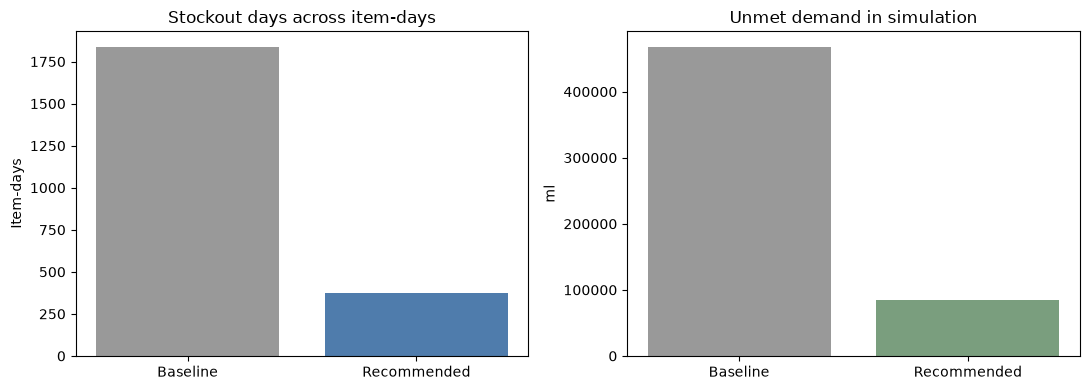

In [7]:
PROTECTION_DAYS = LEAD_TIME_DAYS + REVIEW_PERIOD_DAYS
POLICIES = ["Baseline", "Recommended"]

def selected_weekly_forecast(available_weeks):
    if SELECTED_FORECAST_METHOD == "Eight-week average":
        return float(available_weeks.tail(FORECAST_WINDOW_WEEKS).mean())
    return float(available_weeks.iloc[-1])

simulation_rows = []
order_rows = []
validation_start_week = validation["week_ending"].min()

for key, item_days in daily.groupby(GROUP_COLS, sort=False):
    item_days = item_days.sort_values("Date")
    weekly = (item_days.set_index("Date")["demand_ml"]
              .resample("W-SUN").sum().sort_index())
    weekly = weekly.loc[
        (weekly.index > first_week_end) & (weekly.index <= last_complete_week_end)
    ]

    training_weeks = weekly.loc[weekly.index < validation_start_week].tail(
        FORECAST_WINDOW_WEEKS
    )
    baseline_daily_ml = float(training_weeks.mean()) / 7
    baseline_par_ml = round_up_to_step(baseline_daily_ml * PROTECTION_DAYS)
    baseline_reorder_point_ml = round_up_to_step(
        baseline_daily_ml * LEAD_TIME_DAYS
    )

    item_simulation = item_days.loc[
        item_days["Date"].between(SIMULATION_START, SIMULATION_END)
    ]
    initial_stock_ml = baseline_par_ml

    for policy in POLICIES:
        on_hand_ml = initial_stock_ml
        open_orders = []
        item_simulation_rows = []

        for day_number, row in enumerate(item_simulation.itertuples(index=False)):
            current_date = row.Date
            demand_ml = float(row.demand_ml)

            # 1. Receive only deliveries whose scheduled date has arrived.
            arriving = [order for order in open_orders
                        if order["delivery_date"] <= current_date]
            received_ml = sum(order["quantity_ml"] for order in arriving)
            on_hand_ml += received_ml
            open_orders = [order for order in open_orders
                           if order["delivery_date"] > current_date]

            # 2. Serve demand from available stock; unmet demand is lost.
            fulfilled_ml = min(on_hand_ml, demand_ml)
            unmet_ml = demand_ml - fulfilled_ml
            on_hand_ml -= fulfilled_ml

            # 3-5. Review stock on the review schedule and place an order if needed.
            order_quantity_ml = 0.0
            review_today = day_number % REVIEW_PERIOD_DAYS == 0
            if review_today:
                inventory_position_ml = on_hand_ml + sum(
                    order["quantity_ml"] for order in open_orders
                )

                if policy == "Baseline":
                    target_par_ml = baseline_par_ml
                    reorder_point_ml = baseline_reorder_point_ml
                else:
                    completed_week_end = current_date - pd.Timedelta(
                        days=(current_date.weekday() + 1) % 7
                    )
                    available_weeks = weekly.loc[weekly.index <= completed_week_end]
                    if len(available_weeks) >= FORECAST_WINDOW_WEEKS:
                        forecast_weekly_ml = selected_weekly_forecast(available_weeks)
                    else:
                        forecast_weekly_ml = float(training_weeks.mean())

                    forecast_daily_ml = forecast_weekly_ml / 7
                    demand_so_far = item_days.loc[
                        item_days["Date"] <= current_date, "demand_ml"
                    ].tail(56)
                    daily_std_ml = (
                        float(demand_so_far.std(ddof=1))
                        if len(demand_so_far) > 1 else 0.0
                    )
                    safety_stock_ml = (
                        z_score * daily_std_ml * math.sqrt(PROTECTION_DAYS)
                    )
                    target_par_ml = round_up_to_step(
                        forecast_daily_ml * PROTECTION_DAYS + safety_stock_ml
                    )
                    reorder_point_ml = round_up_to_step(
                        forecast_daily_ml * LEAD_TIME_DAYS + safety_stock_ml
                    )

                if inventory_position_ml <= reorder_point_ml:
                    order_quantity_ml = max(
                        0.0, target_par_ml - inventory_position_ml
                    )
                    if order_quantity_ml > 0:
                        delivery_date = current_date + pd.Timedelta(
                            days=LEAD_TIME_DAYS
                        )
                        new_order = {
                            "delivery_date": delivery_date,
                            "quantity_ml": order_quantity_ml,
                        }
                        open_orders.append(new_order)
                        order_rows.append({
                            **dict(zip(GROUP_COLS, key)),
                            "policy": policy,
                            "order_date": current_date,
                            "delivery_date": delivery_date,
                            "quantity_ml": order_quantity_ml,
                        })

            ending_pipeline_ml = sum(
                order["quantity_ml"] for order in open_orders
            )
            item_simulation_rows.append({
                **dict(zip(GROUP_COLS, key)),
                "policy": policy,
                "date": current_date,
                "demand_ml": demand_ml,
                "fulfilled_ml": fulfilled_ml,
                "unmet_demand_ml": unmet_ml,
                "ending_stock_ml": on_hand_ml,
                "incoming_pipeline_ml": ending_pipeline_ml,
                "received_ml": received_ml,
                "order_placed_ml": order_quantity_ml,
            })

        simulation_rows.extend(item_simulation_rows)

simulation_detail = pd.DataFrame(simulation_rows)
order_log = pd.DataFrame(order_rows, columns=[
    *GROUP_COLS, "policy", "order_date", "delivery_date", "quantity_ml"
])

summary_rows = []
for policy in POLICIES:
    policy_days = simulation_detail.loc[simulation_detail["policy"] == policy]
    policy_orders = order_log.loc[order_log["policy"] == policy]
    average_inventory_ml = (
        policy_days.groupby("date")["ending_stock_ml"].sum().mean()
    )
    fulfilled_total_ml = policy_days["fulfilled_ml"].sum()

    summary_rows.append({
        "Policy": policy,
        "Stockout days (item-days)": int((policy_days["unmet_demand_ml"] > 0).sum()),
        "Unmet demand (ml)": policy_days["unmet_demand_ml"].sum(),
        "Average system inventory (ml)": average_inventory_ml,
        "Replenishment orders": len(policy_orders),
        "Ordered volume (ml)": policy_orders["quantity_ml"].sum(),
        "Turnover over simulation period": (
            fulfilled_total_ml / average_inventory_ml
            if average_inventory_ml > 0 else np.nan
        ),
    })

simulation_summary = pd.DataFrame(summary_rows)
print(f"Simulated {simulation_detail['date'].nunique()} days per item, "
      f"{simulation_detail[GROUP_COLS].drop_duplicates().shape[0]} item combinations.")
display(simulation_summary.round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(simulation_summary["Policy"],
            simulation_summary["Stockout days (item-days)"],
            color=["#999999", "#4f7cac"])
axes[0].set(title="Stockout days across item-days", ylabel="Item-days")
axes[1].bar(simulation_summary["Policy"],
            simulation_summary["Unmet demand (ml)"],
            color=["#999999", "#7a9e7e"])
axes[1].set(title="Unmet demand in simulation", ylabel="ml")
plt.tight_layout()
plt.show()

## 7. Manager view and export

The recommendation table and chart show forecast demand and par by bar and brand. A suggested order is only calculated when the file contains a valid closing-balance record on the source data's final date. That is still a historical position, not live stock. Check the current count, apply pack sizes and supplier minimums, and account for expiry before ordering.

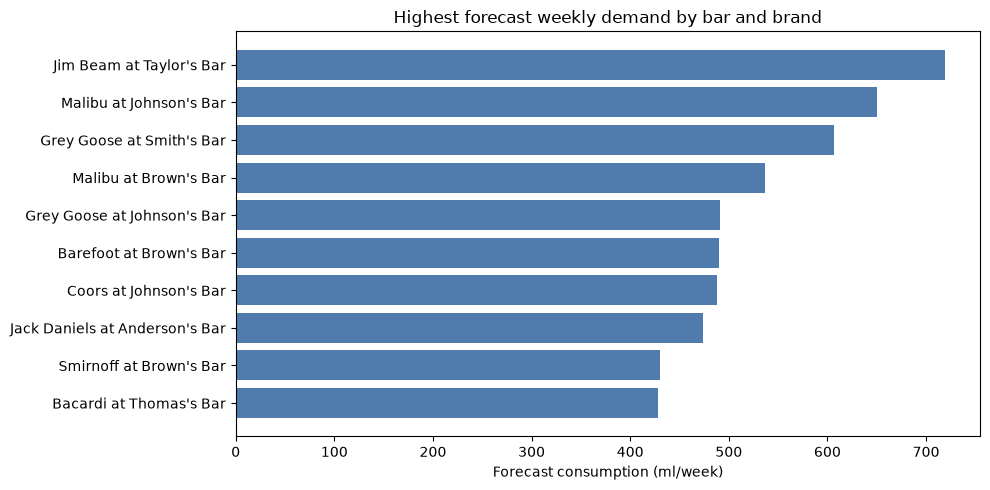

Saved 96 rows to C:\inventory_management_sys\inventory_recommendations.csv
Exported forecast method: Eight-week average


In [8]:
top = recommendations.head(10).sort_values("forecast_weekly_ml")
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top["Brand Name"] + " at " + top["Bar Name"],
        top["forecast_weekly_ml"], color="#4f7cac")
ax.set(title="Highest forecast weekly demand by bar and brand",
       xlabel="Forecast consumption (ml/week)")
plt.tight_layout()
plt.show()

OUTPUT_PATH = Path("inventory_recommendations.csv")
export = recommendations.assign(
    lead_time_days=LEAD_TIME_DAYS,
    review_period_days=REVIEW_PERIOD_DAYS,
    service_level=SERVICE_LEVEL,
    par_rounding_ml=PAR_ROUNDING_ML,
    selection_criterion=SELECTION_CRITERION,
    simulation_baseline="Fixed order-up-to target from first 8 training weeks; no safety stock",
    simulation_recommended="Selected rolling forecast, safety stock, and order-up-to par",
    simulation_lost_sales=True,
    simulation_start=SIMULATION_START.date().isoformat(),
    simulation_end=SIMULATION_END.date().isoformat(),
    source_data_through=as_of.date().isoformat(),
)
export.to_csv(OUTPUT_PATH, index=False)
print(f"Saved {len(export)} rows to {OUTPUT_PATH.resolve()}")
print("Exported forecast method:", SELECTED_FORECAST_METHOD)


## 8. Assumptions to revisit

- Missing dates are filled with zero recorded demand, but this is not evidence of zero use. Record coverage is shown because incomplete logging can understate demand.
- Negative movement quantities, duplicates, missing values, and inventory-balance discrepancies are flagged. Suspicious rows are shown for review; negative consumption is excluded from demand analysis rather than changed to zero.
- The lead time is three days, review interval seven days, service level 95%, and planning increment 50 ml. Confirm supplier timing, pour/pack sizes, and acceptable service levels with managers.
- The eight-week average and previous-week baseline are evaluated on the same chronological validation period. The method with the lowest WAPE is selected; ties use MAE. If total validation demand is zero, MAE is used.
- The simulation starts after the training and validation periods. Both policies use the same zero-filled demand sequence and the same opening-stock assumption, based only on the initial training weeks. Shortages are treated as lost sales, and orders arrive only on or after their scheduled delivery dates.
- Closing balances from this file are historical. A suggested order is populated only when the latest record is dated on the source end date, has a nonnegative closing balance, has no negative quantity or exact-duplicate flag, and its balance discrepancy is within 1 ml. It still requires a live stock check.
- All recommendations are in ml and rounded up to 50 ml. The dataset does not provide pack sizes, costs, supplier constraints, or current stock.
- The file contains about one year of sparse records, so it cannot establish dependable annual seasonality. A complete daily sales and stock ledger would improve the forecasts and the simulation.